# Churn Risk and Retention Targeting for a Music-Streaming Subscription (KKBox)

**Business question.** A subscription company can only contact a limited number of customers. *Which customers are about to churn, and who is worth contacting first?*

**Data.** KKBox churn challenge (Kaggle): ~993K subscribers, 21.5M transactions, member details. "Churn" = no renewal within 30 days after the membership expires.

**What I did (one line per step)**

1. Built a **SQL (DuckDB) pipeline** to clean the data and build labels and features, with data-quality checks.
2. **Checked my own churn labels against Kaggle's official flag**, found they disagreed, found out why, and fixed it.
3. Found that only about **12% of customers are truly "at risk"** (membership expired, not renewed) and that they account for most churn.
4. Compared groups with **Kaplan-Meier curves and log-rank tests** (descriptive survival analysis).
5. Built a **logistic regression** (odds ratios = what drives churn) and checked it against a **tree model**.
6. Turned the predicted probabilities into a **who-to-contact decision** using a simple cost model, with a sensitivity table.

**Leakage rule.** Every feature uses only transactions dated **on or before 2017-02-28**. The March 2017 file is used **only** to build the churn label.

> **How to use this notebook:** run it top to bottom. After every section there is an *Interview note* and a *Your notes* cell. Rewrite them in your own words after you understand the output. That is what you will be asked about.
>
> **Check the numbers:** the numbers quoted in the interview notes come from a full run on the real data. Compare them with your own output and **change any that differ**; never quote a number you cannot see on your screen.

## 1. Setup

In [2]:
import os, sys, time, math, warnings, subprocess, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# install only what is missing (Colab already has most of these)
_pkgs = {"duckdb": "duckdb", "lifelines": "lifelines", "statsmodels": "statsmodels", "sklearn": "scikit-learn"}
_missing = [p for m, p in _pkgs.items() if importlib.util.find_spec(m) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 150)
plt.rcParams["figure.figsize"] = (8, 4.5)

# ---------------- settings ----------------
DATA_DIR   = os.environ.get("KKBOX_DATA_DIR", "/content/data")     # folder with the four Kaggle CSVs
WORK_DIR   = os.environ.get("KKBOX_WORK_DIR", ".")                 # sql/, exports and the database file go here
DB_PATH    = os.path.join(WORK_DIR, "kkbox.duckdb")
SQL_DIR    = os.path.join(WORK_DIR, "sql")
EXPORT_DIR = os.path.join(WORK_DIR, "dashboard_exports")
os.makedirs(SQL_DIR, exist_ok=True); os.makedirs(EXPORT_DIR, exist_ok=True)

FEATURE_CUTOFF    = "2017-02-28"   # features use data up to this date only
RESOLUTION_CUTOFF = "2017-03-31"   # last date of data we can use to see who renewed
CHURN_WINDOW_DAYS = 30             # KKBox rule: churn = no renewal within 30 days after expiry
RANDOM_SEED = 42
COHORT_SAMPLE_PCT = int(os.environ.get("COHORT_SAMPLE_PCT", 100))   # lower (e.g. 10) for a quick trial run
np.random.seed(RANDOM_SEED)
print("data:", DATA_DIR, "| cutoff:", FEATURE_CUTOFF)

data: /content/data | cutoff: 2017-02-28


In [3]:
# Download from Kaggle only if the files are not already there
from pathlib import Path
REQUIRED = ["train.csv", "transactions.csv", "transactions_v2.csv", "members_v3.csv"]
def _have_all(): return all((Path(DATA_DIR) / f).exists() for f in REQUIRED)

if not _have_all():
    from getpass import getpass
    import shutil
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "py7zr", "--upgrade", "kaggle"], check=True)
    import py7zr
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    tok_path = os.path.expanduser("~/.kaggle/access_token")
    with open(tok_path, "w") as f: f.write(getpass("Kaggle API key: "))
    os.chmod(tok_path, 0o600); os.makedirs(DATA_DIR, exist_ok=True)
    for f in REQUIRED:
        subprocess.run(["kaggle", "competitions", "download", "-c", "kkbox-churn-prediction-challenge", "-f", f + ".7z", "-p", DATA_DIR], check=True)
        with py7zr.SevenZipFile(Path(DATA_DIR) / (f + ".7z"), mode="r") as z: z.extractall(path=DATA_DIR)
    for f in REQUIRED:                       # transactions_v2.csv sometimes lands in a sub-folder
        if not (Path(DATA_DIR) / f).exists():
            hits = sorted(Path(DATA_DIR).rglob(f), key=lambda p: len(str(p)))
            if hits: shutil.copy2(hits[0], Path(DATA_DIR) / f)
assert _have_all(), "input files missing"
for f in REQUIRED: print(f"{f:22s}{(Path(DATA_DIR)/f).stat().st_size/2**20:9.1f} MB")

Kaggle API key: ··········
train.csv                  44.5 MB
transactions.csv         1649.2 MB
transactions_v2.csv       110.0 MB
members_v3.csv            408.1 MB


## 2. SQL pipeline (DuckDB)

DuckDB runs inside the notebook and reads the big CSV files directly, so no database server is needed. Each stage is saved as a real `.sql` file in the `sql/` folder (keep that folder in your GitHub repo).

```
raw tables → cleaned tables → labels → features → one modelling table
```

In [4]:
import duckdb
con = duckdb.connect(DB_PATH)
con.execute("PRAGMA memory_limit='6GB'")
con.execute(f"PRAGMA temp_directory='{os.path.join(WORK_DIR, 'duck_tmp')}'")

# values that the .sql files use as {{PLACEHOLDERS}}
PARAMS = {"DATA_DIR": DATA_DIR, "FEATURE_CUTOFF": FEATURE_CUTOFF, "RESOLUTION_CUTOFF": RESOLUTION_CUTOFF,
          "CHURN_WINDOW_DAYS": str(CHURN_WINDOW_DAYS),
          "LABEL_RENEWED": "renewed_extend",   # which renewal rule defines the label (explained in Section 3)
          "CANCEL_AWARE": "1"}                 # 1 = respect cancellation rows when finding the expiry date (Section 3)

def run_sql(name, show=False):
    text = open(os.path.join(SQL_DIR, f"{name}.sql")).read()
    for k, v in PARAMS.items(): text = text.replace("{{" + k + "}}", v)
    t0 = time.time(); res = con.execute(text)
    print(f"[{name}] {time.time()-t0:.0f}s"); return res.df() if show else None

**Step 1: load the raw files**

In [5]:
%%writefile sql/01_load.sql
-- 01_load.sql : raw CSVs -> DuckDB tables (dates parsed from YYYYMMDD integers)
CREATE OR REPLACE TABLE raw_train AS
SELECT * FROM read_csv_auto('{{DATA_DIR}}/train.csv');

CREATE OR REPLACE TABLE raw_members AS
SELECT * FROM read_csv('{{DATA_DIR}}/members_v3.csv',
    types = {'registration_init_time': 'DATE'}, dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn_v2 AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions_v2.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

Writing sql/01_load.sql


In [6]:
run_sql("01_load")
if COHORT_SAMPLE_PCT < 100:   # optional shortcut for a quick trial run
    con.execute(f"CREATE OR REPLACE TABLE raw_train AS SELECT * FROM raw_train USING SAMPLE {COHORT_SAMPLE_PCT} PERCENT (bernoulli, {RANDOM_SEED})")
print(con.sql("SELECT (SELECT COUNT(*) FROM raw_train) AS customers, (SELECT COUNT(*) FROM raw_members) AS members, "
              "(SELECT COUNT(*) FROM raw_txn) AS transactions_to_feb, (SELECT COUNT(*) FROM raw_txn_v2) AS transactions_march").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[01_load] 73s
   customers  members  transactions_to_feb  transactions_march
0     992931  6769473             21547746             1431009


**Step 2: data-quality audit on the full tables**

In [7]:
%%writefile sql/02_quality_checks.sql
-- 02_quality_checks.sql : null audits, outlier ages, invalid expiry-before-transaction dates, orphan keys
SELECT 'transactions rows (v1)' AS check_name, COUNT(*) AS n FROM raw_txn
UNION ALL SELECT 'transactions rows (v2)', COUNT(*) FROM raw_txn_v2
UNION ALL SELECT 'train cohort size', COUNT(*) FROM raw_train
UNION ALL SELECT 'expire date < transaction date',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < transaction_date
UNION ALL SELECT 'expire date before 2000',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < DATE '2000-01-01'
UNION ALL SELECT 'null expire / amount / plan days',
       COUNT(*) FROM raw_txn
       WHERE membership_expire_date IS NULL OR actual_amount_paid IS NULL OR payment_plan_days IS NULL
UNION ALL SELECT 'members: age outside 1-99',
       COUNT(*) FROM raw_members WHERE bd <= 0 OR bd >= 100
UNION ALL SELECT 'members: missing gender',
       COUNT(*) FROM raw_members WHERE gender IS NULL
UNION ALL SELECT 'members: duplicate msno',
       COUNT(*) - COUNT(DISTINCT msno) FROM raw_members
UNION ALL SELECT 'cohort customers with no transactions',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_txn x WHERE x.msno = t.msno)
UNION ALL SELECT 'cohort customers missing from members',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_members m WHERE m.msno = t.msno);

Writing sql/02_quality_checks.sql


In [8]:
qc = run_sql("02_quality_checks", show=True)
n_txn = int(qc.loc[qc.check_name == "transactions rows (v1)", "n"].iloc[0])
qc["pct_of_table"] = np.where(qc.check_name.isin(["expire date < transaction date", "expire date before 2000"]), (100 * qc.n / n_txn).round(3), np.nan)
display(qc); qc.to_csv(os.path.join(EXPORT_DIR, "data_quality_audit.csv"), index=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[02_quality_checks] 13s


,check_name,n,pct_of_table
0,transactions rows (v1),21547746,NaN
1,transactions rows (v2),1431009,NaN
2,train cohort size,992931,NaN
3,expire date < transaction date,153660,0.713
4,expire date before 2000,1778,0.008
5,null expire / amount / plan days,0,NaN
6,members: age outside 1-99,4546009,NaN
7,members: missing gender,4429505,NaN
8,members: duplicate msno,0,NaN
9,cohort customers with no transactions,0,NaN


**Step 3: clean the data.** Remove impossible rows (expiry date *before* the transaction date), keep only transactions up to the cutoff, and flag customers with an invalid age.

In [9]:
%%writefile sql/03_staging.sql
-- 03_staging.sql
CREATE OR REPLACE TABLE stg_txn AS
SELECT t.*
FROM raw_txn t
JOIN raw_train c USING (msno)
WHERE t.transaction_date <= DATE '{{FEATURE_CUTOFF}}'
  AND t.membership_expire_date IS NOT NULL
  AND t.membership_expire_date >= t.transaction_date;

CREATE OR REPLACE TABLE stg_members AS
SELECT m.msno,
       m.city,
       m.registered_via,
       m.registration_init_time,
       CASE WHEN m.bd BETWEEN 1 AND 99 THEN m.bd END  AS bd,
       (m.bd IS NULL OR m.bd NOT BETWEEN 1 AND 99)    AS age_missing,
       COALESCE(m.gender, 'unknown')                  AS gender
FROM raw_members m
JOIN raw_train c USING (msno)
QUALIFY ROW_NUMBER() OVER (PARTITION BY m.msno ORDER BY m.registration_init_time) = 1;

Writing sql/03_staging.sql


In [10]:
run_sql("03_staging")
print(con.sql("SELECT (SELECT COUNT(*) FROM stg_txn) AS clean_transactions, (SELECT COUNT(*) FROM stg_members) AS clean_members").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[03_staging] 26s
   clean_transactions  clean_members
0            15817793         877161


**Step 4: build the churn label.** The next section explains the three decisions inside this file, so here is the idea:

* `last_expire` = the date the customer's membership ends, **as known on 28 Feb**.
* Churn = no renewal within 30 days after that date (KKBox's own rule). We look for renewals in `transactions_v2` (March).
* If the 30-day window ends after 31 March we cannot see the outcome, so those customers are **censored** (their outcome is unknown, not "no churn").

In [11]:
%%writefile sql/04_labels.sql
-- 04_labels.sql  (cancel-aware version)
-- CANCEL_AWARE = 1 : if a customer's most recent transaction is a cancellation, the membership ends at THAT row's expiry date
--                    (a cancel row can move the expiry EARLIER than the max over older rows)
-- CANCEL_AWARE = 0 : original rule (max expiry over all rows) -> reproduces v1 / the reconciliation numbers
CREATE OR REPLACE TABLE last_state AS
WITH ranked AS (
    SELECT msno, membership_expire_date, is_cancel,
           ROW_NUMBER() OVER (PARTITION BY msno ORDER BY transaction_date DESC, membership_expire_date DESC) AS rn,
           MAX(membership_expire_date) OVER (PARTITION BY msno)                                              AS max_expire
    FROM stg_txn
)
SELECT msno,
       CASE WHEN {{CANCEL_AWARE}} = 1 AND is_cancel = 1 THEN membership_expire_date ELSE max_expire END AS last_expire
FROM ranked
WHERE rn = 1;

CREATE OR REPLACE TABLE labels AS
WITH base AS (
    SELECT msno, last_expire, last_expire + {{CHURN_WINDOW_DAYS}} AS window_end
    FROM last_state
    WHERE last_expire + {{CHURN_WINDOW_DAYS}} > DATE '{{FEATURE_CUTOFF}}'
),
renew AS (
    SELECT b.msno,
           MAX(CASE WHEN v.transaction_date >  b.last_expire THEN 1 ELSE 0 END) AS renewed_strict,
           MAX(CASE WHEN v.transaction_date >= b.last_expire THEN 1 ELSE 0 END) AS renewed_sameday,
           MAX(CASE WHEN v.membership_expire_date > b.last_expire THEN 1 ELSE 0 END) AS renewed_extend
    FROM base b
    JOIN raw_txn_v2 v ON v.msno = b.msno
    WHERE v.transaction_date >  DATE '{{FEATURE_CUTOFF}}'
      AND v.transaction_date <= b.window_end
    GROUP BY b.msno
),
flagged AS (
    SELECT b.msno, b.last_expire, b.window_end,
           (b.window_end <= DATE '{{RESOLUTION_CUTOFF}}')  AS resolvable,
           COALESCE(r.renewed_strict, 0)                   AS renewed_strict,
           COALESCE(r.renewed_sameday, 0)                  AS renewed_sameday,
           COALESCE(r.renewed_extend, 0)                   AS renewed_extend
    FROM base b
    LEFT JOIN renew r USING (msno)
)
SELECT msno, last_expire, resolvable, renewed_strict, renewed_sameday, renewed_extend,
       CASE WHEN resolvable AND renewed_strict  = 0 THEN 1 ELSE 0 END AS event_strict,
       CASE WHEN resolvable AND renewed_sameday = 0 THEN 1 ELSE 0 END AS event_sameday,
       CASE WHEN resolvable AND renewed_extend  = 0 THEN 1 ELSE 0 END AS event_extend,
       CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN 1 ELSE 0 END AS event,
       DATEDIFF('day', DATE '{{FEATURE_CUTOFF}}',
                CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN window_end
                     ELSE DATE '{{RESOLUTION_CUTOFF}}' END)            AS duration
FROM flagged;

Writing sql/04_labels.sql


In [12]:
run_sql("04_labels")
print(con.sql("SELECT COUNT(*) AS customers, SUM(resolvable::INT) AS outcome_observable, SUM(event) AS churn_events FROM labels").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 26s
   customers  outcome_observable  churn_events
0     987567            121280.0       57981.0


**Step 5: build the features** (all from data up to 28 Feb)

In [13]:
%%writefile sql/05_features.sql
-- 05_features.sql : strictly pre-cutoff (stg_txn only contains transaction_date <= cutoff)
CREATE OR REPLACE TABLE txn_features AS
WITH ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY msno
                              ORDER BY transaction_date DESC, membership_expire_date DESC) AS rn
    FROM stg_txn
),
last_txn AS (
    SELECT msno,
           payment_method_id  AS last_payment_method,
           payment_plan_days  AS last_plan_days,
           is_auto_renew      AS last_auto_renew,
           is_cancel          AS last_is_cancel
    FROM ranked
    WHERE rn = 1
),
agg AS (
    SELECT msno,
           COUNT(*)                                            AS n_transactions,
           SUM(is_cancel)                                      AS n_cancels,
           AVG(is_auto_renew)                                  AS auto_renew_ratio,
           AVG(payment_plan_days)                              AS avg_plan_days,
           SUM(actual_amount_paid)                             AS total_amount_paid,
           SUM(payment_plan_days)                              AS total_plan_days,
           COALESCE(AVG(1 - actual_amount_paid / NULLIF(plan_list_price, 0)), 0) AS avg_discount_ratio,
           COUNT(DISTINCT payment_method_id)                   AS n_payment_methods,
           MIN(transaction_date)                               AS first_txn,
           MAX(transaction_date)                               AS last_txn_date,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN 1 ELSE 0 END)         AS n_txn_last_90d,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN is_cancel ELSE 0 END) AS n_cancel_last_90d
    FROM stg_txn
    GROUP BY msno
)
SELECT a.*,
       l.* EXCLUDE (msno),
       a.n_cancels * 1.0 / a.n_transactions                                    AS cancel_rate,
       DATEDIFF('day', a.last_txn_date, DATE '{{FEATURE_CUTOFF}}')             AS days_since_last_txn,
       a.total_amount_paid * 30.0 / GREATEST(a.total_plan_days, 30)            AS spend_per_30d
FROM agg a
JOIN last_txn l USING (msno);

Writing sql/05_features.sql


In [14]:
run_sql("05_features")
print(con.sql("SELECT COUNT(*) AS customers_with_features FROM txn_features").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[05_features] 47s
   customers_with_features
0                   992928


**Step 6: one modelling table**, followed by safety checks that no feature uses data after the cut-off

In [15]:
%%writefile sql/06_model_table.sql
-- 06_model_table.sql
-- `resolvable` and `last_expire` are kept ONLY for diagnostics (censoring-bias check); they are never model inputs.
-- `event_strict/sameday/extend` are kept only for label-quality comparison.
-- `is_churn_official` (Kaggle's label) is an EVALUATION / CALIBRATION target only - never a feature.
CREATE OR REPLACE TABLE model_table AS
SELECT lb.msno, lb.duration, lb.event, lb.event_strict, lb.event_sameday, lb.event_extend, lb.resolvable, lb.last_expire,
       tr.is_churn AS is_churn_official,
       m.city, m.registered_via, m.gender, m.bd,
       COALESCE(m.age_missing, TRUE) AS age_missing,        -- customers absent from members_v3 -> age unknown
       DATEDIFF('day', COALESCE(m.registration_init_time, f.first_txn), DATE '{{FEATURE_CUTOFF}}') AS tenure_days,
       f.* EXCLUDE (msno, first_txn, last_txn_date, total_plan_days)
FROM labels lb
LEFT JOIN raw_train tr USING (msno)
LEFT JOIN stg_members m USING (msno)
LEFT JOIN txn_features f USING (msno);

Writing sql/06_model_table.sql


In [16]:
run_sql("06_model_table")

# ---------- safety checks ----------
latest = con.sql("SELECT MAX(transaction_date) FROM stg_txn").fetchone()[0]
assert str(latest) <= FEATURE_CUTOFF, f"features use data after the cutoff: {latest}"
assert con.sql("SELECT COUNT(*) - COUNT(DISTINCT msno) FROM model_table").fetchone()[0] == 0, "duplicate customers"
assert con.sql("SELECT COUNT(*) FROM model_table WHERE n_transactions IS NULL OR duration IS NULL").fetchone()[0] == 0, "unexpected NULLs"
print(f"OK: latest transaction used for features = {latest} (cutoff {FEATURE_CUTOFF}) | no duplicate customers | no NULLs in core columns")
print(con.sql("SELECT COUNT(*) AS customers FROM model_table").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 8s
OK: latest transaction used for features = 2017-02-28 (cutoff 2017-02-28) | no duplicate customers | no NULLs in core columns
   customers
0     987567


*Interview note (rewrite in your own words):* "I did the heavy lifting in SQL because the transaction table has 21 million rows. I used a CTE with a window function (`ROW_NUMBER`) to get each customer's most recent transaction, and `LEFT JOIN`s so that customers without a member record were kept."

## 3. Is my churn label correct? (checking it against Kaggle's official flag)

Kaggle provides its own churn flag (`is_churn`). I built my own label from the transactions so that I could have a time dimension, but then **compared the two**. Three choices in how I define "renewed" matter:

| decision | options |
|---|---|
| **What counts as a renewal?** | *strict*: a transaction after the expiry date. *same-day*: on or after the expiry date. *extended*: any transaction that pushes the expiry date further out (also catches early renewals) |
| **When does the membership end?** | *max expiry*: the latest expiry date over all rows. *cancel-aware*: if the **most recent** transaction is a cancellation, the membership ends at **that** row's expiry date |

Metrics against Kaggle's flag (churners are rare, so **accuracy is misleading**: predicting "nobody churns" is 94% accurate):
**precision** = of those I call churners, how many really are; **recall** = of the real churners, how many I find; **Cohen's kappa** = agreement beyond chance.

One detail: the cancel-aware rule moves some customers' expiry to *before* the cut-off, so they had **already churned** before the prediction date and are **set aside** (they leave the modelling table). To compare fairly, set-aside customers are counted as "predicted churn" on the full 992,931-customer cohort.

*(This cell rebuilds the labels twice, so it takes about 3 minutes on the full data.)*

In [17]:
def confusion_metrics(TP, FP, FN, TN):
    n = TP + FP + FN + TN
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    po = (TP + TN) / n; pe = ((TP + FP) * (TP + FN) + (FN + TN) * (FP + TN)) / n**2
    return dict(precision=round(prec, 4), recall=round(rec, 4), F1=round(2 * prec * rec / max(prec + rec, 1e-12), 4), kappa=round((po - pe) / (1 - pe), 4))

def cohort_confusion(event_col):
    """Compare a label column with Kaggle's flag on the FULL cohort. Customers missing from model_table
    (already churned before the cutoff) count as predicted churn."""
    t = con.sql(f"""SELECT t.is_churn AS y, COALESCE(m.{event_col}, 1) AS pred, COUNT(*) AS n
                    FROM raw_train t LEFT JOIN model_table m USING (msno) GROUP BY 1, 2""").df()
    f = lambda y, p: int(t[(t.y == y) & (t.pred == p)].n.sum())
    return f(1, 1), f(0, 1), f(1, 0), f(0, 0)

BUCKET_SQL = f"""
SELECT CASE WHEN last_expire <= DATE '2017-03-01' THEN 'a: expires by 1 Mar (at risk)'
            WHEN last_expire <= DATE '2017-03-15' THEN 'b: 2-15 Mar' ELSE 'c: 16-31 Mar' END AS last_expire_bucket,
       last_is_cancel, COUNT(*) AS customers, ROUND(AVG(is_churn_official), 3) AS official_churn_rate
FROM model_table GROUP BY 1, 2 ORDER BY 1, 2"""

rows, buckets = [], {}
n_cohort = con.sql("SELECT COUNT(*) FROM raw_train").fetchone()[0]
for flag, expiry_name in [("0", "max expiry over all rows"), ("1", "cancel-aware (latest transaction)")]:
    PARAMS["CANCEL_AWARE"] = flag
    run_sql("04_labels"); run_sql("06_model_table")
    n_model = con.sql("SELECT COUNT(*) FROM model_table").fetchone()[0]
    for col, rule_name in [("event_strict", "strict (after expiry)"), ("event_sameday", "same-day (on/after expiry)"), ("event_extend", "membership extended")]:
        rows.append({"expiry rule": expiry_name, "renewal rule": rule_name, "customers set aside": n_cohort - n_model,
                     **confusion_metrics(*cohort_confusion(col))})
    buckets[expiry_name] = con.sql(BUCKET_SQL).df()
    if flag == "0":
        chk = con.sql("SELECT COUNT(*) AS rows, SUM(resolvable::INT) AS at_risk, SUM(event_strict) AS strict_events FROM labels").df().iloc[0]
        print("SQL (first rule) gives:", chk.to_dict(), "\nMy original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)\n")

label_table = pd.DataFrame(rows); display(label_table)
label_table.to_csv(os.path.join(EXPORT_DIR, "label_quality.csv"), index=False)

PARAMS["CANCEL_AWARE"] = "1"                       # final choice
run_sql("04_labels"); run_sql("06_model_table")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 24s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 8s
SQL (first rule) gives: {'rows': 992928.0, 'at_risk': 121370.0, 'strict_events': 74396.0} 
My original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 27s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 6s


**Why the cancel-aware rule?** Look at customers whose *latest* transaction was a cancellation. Under the "max expiry" rule they looked like safe, already-renewed customers, but Kaggle says most of them churned:

In [18]:
for name, tb in buckets.items():
    print(f"--- expiry rule: {name} ---"); display(tb)
print("Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).")
print("The cancel-aware rule recognises that their membership really ended earlier.")

--- expiry rule: max expiry over all rows ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105212,0.308
1,a: expires by 1 Mar (at risk),1,16158,0.928
2,b: 2-15 Mar,0,388880,0.011
3,b: 2-15 Mar,1,5473,0.810
4,c: 16-31 Mar,0,474322,0.011
5,c: 16-31 Mar,1,2883,0.787


--- expiry rule: cancel-aware (latest transaction) ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105212,0.308
1,a: expires by 1 Mar (at risk),1,16069,0.912
2,b: 2-15 Mar,0,388880,0.011
3,b: 2-15 Mar,1,1845,0.532
4,c: 16-31 Mar,0,474322,0.011
5,c: 16-31 Mar,1,1240,0.606


Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).
The cancel-aware rule recognises that their membership really ended earlier.


In [19]:
first = label_table[(label_table["expiry rule"].str.startswith("max")) & (label_table["renewal rule"].str.startswith("strict"))].iloc[0]
chosen = label_table[(label_table["expiry rule"].str.startswith("cancel")) & (label_table["renewal rule"].str.startswith("membership"))].iloc[0]
top = label_table.sort_values("kappa", ascending=False).iloc[0]
print(f"Original rule : recall {first.recall}, precision {first.precision}, kappa {first.kappa}")
print(f"Chosen rule   : recall {chosen.recall}, precision {chosen.precision}, kappa {chosen.kappa}  (cancel-aware expiry + membership-extended renewal)")
print(f"Highest kappa in the table: {top['expiry rule']} + {top['renewal rule']} (kappa {top.kappa}). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.")
print(f"Customers set aside (already churned before the cut-off, or no history): {int(chosen['customers set aside']):,}")

Original rule : recall 0.7397, precision 0.6311, kappa 0.6574
Chosen rule   : recall 0.8206, precision 0.8222, kappa 0.8092  (cancel-aware expiry + membership-extended renewal)
Highest kappa in the table: cancel-aware (latest transaction) + membership extended (kappa 0.8092). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.
Customers set aside (already churned before the cut-off, or no history): 5,363


**What is still not explained.** About 11K customers have *no* March transaction at all, so my label says "churned", but Kaggle says they stayed. I could not fully explain these (see Limitations). This is the main remaining label error, and it is why I use **Kaggle's official flag as the target** for modelling later, and my own label only for the descriptive survival analysis.

*Interview note:* "I didn't trust my own label, so I validated it against Kaggle's. Precision was only 63%: same-day and early renewals were being mislabelled as churn, and cancellation rows were ignored. After fixing both, recall went from about 0.74 to 0.82 and kappa from about 0.66 to about 0.81."

*Your notes (write 2-3 lines yourself):*

## 4. Who is actually at risk?

My label can only observe an outcome when the 30-day window ends inside the data (before 31 March). That is exactly the group whose membership **has already expired (or expires by 1 March) and who have not renewed**. I call them the **at-risk pool**. This is known on 28 Feb, so using it to decide who to model is not leakage.

Everyone else already renewed recently and is mostly safe. Let me check that with Kaggle's flag.

In [20]:
raw = con.sql("SELECT * FROM model_table").df()
raw["in_pool"] = raw["resolvable"].astype(bool)

facts = raw.groupby("in_pool").agg(customers=("msno", "size"), official_churners=("is_churn_official", "sum"),
                                   official_churn_rate=("is_churn_official", "mean"))
facts.index = facts.index.map({True: "at-risk pool", False: "everyone else"}); facts["share_of_customers"] = facts.customers / facts.customers.sum()
display(facts.round(4))
cover = facts.loc["at-risk pool", "official_churners"] / facts.official_churners.sum()
print(f"The pool is {facts.loc['at-risk pool','share_of_customers']:.1%} of customers but contains {cover:.1%} of all remaining churners.")
print(f"Overall churn rate is only {raw.is_churn_official.mean():.1%}, so 'accuracy' would be ~{1 - raw.is_churn_official.mean():.0%} even for a model that predicts nobody churns.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customers,official_churners,official_churn_rate,share_of_customers
in_pool,,,,
everyone else,866287,11114,0.0128,0.8772
at-risk pool,121280,47039,0.3879,0.1228


The pool is 12.3% of customers but contains 80.9% of all remaining churners.
Overall churn rate is only 5.9%, so 'accuracy' would be ~94% even for a model that predicts nobody churns.


**How different is the pool from the rest?** Standardized mean difference (SMD) = difference in means divided by the pooled standard deviation. Values beyond about 0.5 mean the groups are clearly different.

In [21]:
cols = ["days_since_last_txn", "auto_renew_ratio", "last_auto_renew", "n_txn_last_90d", "n_transactions", "last_is_cancel", "last_plan_days", "tenure_days"]
a, b = raw[raw.in_pool], raw[~raw.in_pool]
smd = pd.DataFrame({"mean_pool": [a[c].astype(float).mean() for c in cols], "mean_rest": [b[c].astype(float).mean() for c in cols]}, index=cols)
smd["SMD"] = [(a[c].astype(float).mean() - b[c].astype(float).mean()) / math.sqrt((a[c].astype(float).var() + b[c].astype(float).var()) / 2) for c in cols]
display(smd.round(3))
print("The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).")

,mean_pool,mean_rest,SMD
days_since_last_txn,70.316,14.327,0.776
auto_renew_ratio,0.595,0.915,-0.839
last_auto_renew,0.586,0.930,-0.876
n_txn_last_90d,1.917,2.875,-1.090
n_transactions,11.571,16.531,-0.604
last_is_cancel,0.132,0.004,0.530
last_plan_days,64.696,29.986,0.522
tenure_days,1109.407,1185.650,-0.073


The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).


*Interview note:* "Only about 12% of customers are at risk at the cut-off, but they contain about 80% of the churners. So the model and the campaign should focus on them. The other 88% already renewed and churn at about 1%."

*Your notes:*

## 5. Preparing the at-risk pool for modelling

* **Target:** Kaggle's official churn flag (`is_churn_official`), the cleanest outcome available.
* **Missing members:** customers with no member record get `age_missing = 1`, gender "unknown", city "missing".
* **Rare categories** (under 1%) are pooled into "other".
* Skewed counts and amounts use `log1p`, then every numeric feature is standardized with **training-set** mean and SD, so a coefficient means "per +1 SD".
* **Split:** 75% train / 25% test, stratified on churn. The test set is used only for final reporting.

In [22]:
from sklearn.model_selection import train_test_split

P = raw[raw["in_pool"]].reset_index(drop=True).copy()

# DuckDB can return pandas "nullable" types; convert numeric ones to plain floats
for c in P.columns:
    if c in ("msno", "city", "registered_via", "last_payment_method"): continue
    if pd.api.types.is_extension_array_dtype(P[c].dtype) and (pd.api.types.is_numeric_dtype(P[c].dtype) or pd.api.types.is_bool_dtype(P[c].dtype)):
        P[c] = P[c].astype("float64")

n_no_member = int(P["city"].isna().sum())
P["age_missing"] = P["age_missing"].fillna(1).astype(int)
P["gender"] = P["gender"].fillna("unknown")
print(f"At-risk pool: {len(P):,} customers | {n_no_member:,} have no member record")

def _as_cat(v):
    if v is None or v is pd.NA or (isinstance(v, (float, np.floating)) and math.isnan(v)): return "missing"
    if isinstance(v, (float, np.floating)) and float(v).is_integer(): return str(int(v))
    return str(v)
def pool_rare(s, min_frac=0.01):
    s = s.astype("object").map(_as_cat); keep = s.value_counts(normalize=True)
    return s.where(s.isin(set(keep[keep >= min_frac].index)), "other")
for c in ["city", "registered_via", "last_payment_method"]: P[c] = pool_rare(P[c])

# group columns for the survival curves (built from the raw values, before any scaling)
P["spend_raw"] = P["spend_per_30d"].astype(float)
P["auto_renew_group"] = pd.cut(P.auto_renew_ratio, [-0.01, 0.33, 0.66, 1.0], labels=["low auto-renew", "medium auto-renew", "high auto-renew"]).astype(str)
P["plan_group"] = pd.cut(P.last_plan_days, [-1, 7, 30, 90, 10**6], labels=["<=7d plan", "8-30d plan", "31-90d plan", ">90d plan"]).astype(str)
P["payment_group"] = "pm_" + P.last_payment_method.where(P.last_payment_method.isin(P.last_payment_method.value_counts().index[:5]), "other")
P["tenure_group"] = pd.cut(P.tenure_days.clip(lower=0), [-1, 180, 365, 730, 10**7], labels=["<6 months", "6-12 months", "1-2 years", ">2 years"]).astype(str)
P["cancel_history"] = np.where(P.n_cancels > 0, "has cancelled before", "never cancelled")

NUMERIC = ["bd", "tenure_days", "n_transactions", "n_cancels", "auto_renew_ratio", "avg_plan_days", "total_amount_paid", "avg_discount_ratio",
           "cancel_rate", "n_payment_methods", "n_txn_last_90d", "n_cancel_last_90d", "days_since_last_txn", "last_plan_days", "spend_per_30d"]
FLAGS = ["age_missing", "last_auto_renew", "last_is_cancel"]
LOG_COLS = ["tenure_days", "n_transactions", "n_cancels", "total_amount_paid", "avg_plan_days", "last_plan_days", "n_txn_last_90d",
            "n_cancel_last_90d", "days_since_last_txn", "spend_per_30d", "n_payment_methods"]
P["tenure_days"] = P.tenure_days.clip(lower=0); P["days_since_last_txn"] = P.days_since_last_txn.clip(lower=0)
for c in LOG_COLS: P[c] = np.log1p(P[c].astype(float))

dummies = pd.get_dummies(P[["city", "gender", "registered_via", "last_payment_method"]], drop_first=True, dtype=float)
P = pd.concat([P, dummies], axis=1)

idx_train, idx_test = train_test_split(np.arange(len(P)), test_size=0.25, random_state=RANDOM_SEED, stratify=P["is_churn_official"])
P["bd"] = P["bd"].fillna(P.loc[idx_train, "bd"].median())              # train-only median
mu, sd = P.loc[idx_train, NUMERIC].mean(), P.loc[idx_train, NUMERIC].std().replace(0, 1)
P[NUMERIC] = ((P[NUMERIC] - mu) / sd).clip(-6, 6)

const = [c for c in NUMERIC + FLAGS + list(dummies.columns) if P.loc[idx_train, c].std() == 0]
ALL_FEATURES = [c for c in NUMERIC + FLAGS + list(dummies.columns) if c not in const]
assert P[ALL_FEATURES].isna().sum().sum() == 0
print(f"train {len(idx_train):,} | test {len(idx_test):,} | features {len(ALL_FEATURES)} | churn rate train {P.loc[idx_train,'is_churn_official'].mean():.3f}, test {P.loc[idx_test,'is_churn_official'].mean():.3f}")

At-risk pool: 121,280 customers | 11,283 have no member record
train 90,960 | test 30,320 | features 48 | churn rate train 0.388, test 0.388


## 6. Follow-up and survival-analysis limitation

The classification model predicts Kaggle's official binary churn label using features available by **28 February 2017**. We separately audited whether the available post-cutoff transactions support time-to-event modelling.

The current custom outcome uses `last_expire + 30 days` as a confirmation-window endpoint. This is not the observed date a customer actually churned. Follow-up is also incomplete for most eligible customers by the conservative observation end (**27 March 2017**), and renewal changes the interpretation of the non-renewal event. Therefore, this notebook reports the 30-day outcome/follow-up audit but **does not fit or claim a conventional Kaplan–Meier or Cox model** from these constructed times.

A defensible survival model would require a well-defined event time, a time origin, and reliable censoring/renewal records. The current dataset does not establish that endpoint sufficiently. The classification pipeline remains unchanged.

## 7. What drives churn? Logistic regression and odds ratios

**Logistic regression** models the log-odds of churn. The **odds ratio** (OR) of a feature is how much the *odds* of churn are multiplied when the feature goes up by 1 SD (for 0/1 flags: from 0 to 1). OR above 1 = more churn, below 1 = less. These are **associations, not causes**.

First, **multicollinearity**: if two features carry almost the same information, their coefficients become unstable. The variance inflation factor (VIF) measures this; above 10 is a warning, so I drop the worst feature and repeat.

In [31]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

def vif_table(df, cols):
    X = add_constant(df[cols].astype(float), has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); v = [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]
    return pd.Series(np.minimum(v, 1e6), index=cols).sort_values(ascending=False)

num_now = [c for c in NUMERIC if c in ALL_FEATURES]
vs = P.loc[idx_train, num_now].sample(min(100_000, len(idx_train)), random_state=RANDOM_SEED)
display(vif_table(vs, num_now).round(2).head(6).to_frame("VIF (before)"))
dropped = []
while True:
    v = vif_table(vs, num_now)
    if v.iloc[0] <= 10: break
    dropped.append((v.index[0], round(float(v.iloc[0]), 1))); num_now.remove(v.index[0])
print("Dropped for VIF > 10:", dropped, "| largest VIF now:", round(vif_table(vs, num_now).iloc[0], 2))
FEATURES = num_now + [c for c in ALL_FEATURES if c not in NUMERIC]

,VIF (before)
total_amount_paid,45.96
n_transactions,35.50
avg_plan_days,18.36
spend_per_30d,13.59
n_txn_last_90d,6.03
last_plan_days,5.69


Dropped for VIF > 10: [('total_amount_paid', 46.0)] | largest VIF now: 6.03


In [32]:

import statsmodels.api as sm
import numpy as np
import pandas as pd

# Split using your existing train/test indices
X_train = P.loc[idx_train, FEATURES].astype(float).copy()
X_test  = P.loc[idx_test, FEATURES].astype(float).copy()

ytr = P.loc[idx_train, "is_churn_official"].astype(int)
yte = P.loc[idx_test, "is_churn_official"].astype(int).values

# Replace infinities and impute missing values using training data only
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test  = X_test.replace([np.inf, -np.inf], np.nan)

medians = X_train.median()
X_train = X_train.fillna(medians).fillna(0)
X_test  = X_test.fillna(medians).fillna(0)

# Remove constant columns
constant_cols = X_train.columns[X_train.nunique(dropna=False) <= 1].tolist()
X_train = X_train.drop(columns=constant_cols)
X_test  = X_test.drop(columns=constant_cols, errors="ignore")

# Remove exact duplicate columns
duplicate_cols = X_train.columns[X_train.T.duplicated()].tolist()
X_train = X_train.drop(columns=duplicate_cols)
X_test  = X_test.drop(columns=duplicate_cols, errors="ignore")

print("Removed constant columns:", constant_cols)
print("Removed duplicate columns:", duplicate_cols)

# Add intercept
Xtr = sm.add_constant(X_train, has_constant="add")
Xte = sm.add_constant(X_test, has_constant="add")
Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)

# Fit using the pseudoinverse-based optimizer rather than requiring
# an invertible information matrix during the initial optimization.
logit = sm.Logit(ytr, Xtr).fit(
    method="lbfgs",
    disp=0,
    maxiter=500
)

print(logit.summary())

# Odds ratios and confidence intervals
ci = logit.conf_int()
odds = pd.DataFrame({
    "feature": logit.params.index,
    "odds_ratio": np.exp(np.clip(logit.params.values, -30, 30)),
    "ci_low": np.exp(np.clip(ci[0].values, -30, 30)),
    "ci_high": np.exp(np.clip(ci[1].values, -30, 30)),
    "p_value": logit.pvalues.values
})

odds = odds[odds.feature != "const"].copy()
odds["effect"] = np.where(
    odds.odds_ratio > 1, "higher churn odds", "lower churn odds"
)
odds = odds.sort_values("odds_ratio", ascending=False)

display(odds.head(15).round(4))
odds.to_csv(os.path.join(EXPORT_DIR, "odds_ratios.csv"), index=False)

p_logit_te = logit.predict(Xte).values


Removed constant columns: []
Removed duplicate columns: ['registered_via_missing']
                           Logit Regression Results                           
Dep. Variable:      is_churn_official   No. Observations:                90960
Model:                          Logit   Df Residuals:                    90913
Method:                           MLE   Df Model:                           46
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.4316
Time:                        18:24:06   Log-Likelihood:                -34527.
converged:                       True   LL-Null:                       -60741.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         1.6665      0.117     14.200      0.000       1.436       1.896
bd 

,feature,odds_ratio,ci_low,ci_high,p_value,effect
17,last_is_cancel,339.2305,280.4295,410.3611,0.0000,higher churn odds
29,city_missing,3.8852,3.3550,4.4993,0.0000,higher churn odds
12,days_since_last_txn,1.9640,1.8711,2.0615,0.0000,higher churn odds
11,n_cancel_last_90d,1.5702,1.4774,1.6689,0.0000,higher churn odds
34,registered_via_7,1.3955,1.2468,1.5621,0.0000,higher churn odds
15,age_missing,1.1515,1.0482,1.2650,0.0033,higher churn odds
5,auto_renew_ratio,1.1235,1.0544,1.1971,0.0003,higher churn odds
1,bd,1.0767,1.0567,1.0970,0.0000,higher churn odds
8,cancel_rate,1.0583,1.0110,1.1078,0.0152,higher churn odds
31,gender_male,1.0494,1.0018,1.0993,0.0418,higher churn odds


*Interview note:* "The strongest signals are: last transaction was a cancellation (odds many times higher), auto-renew switched on (odds far lower) and days since the last transaction. These are predictive associations, not proof that cancelling *causes* churn. A cancellation is partly the customer announcing their intention."

*Your notes:*

## 8. How good are the predictions? (and is a fancier model worth it?)

On the **held-out test set** (at-risk pool only) I compare four scorers:

1. **Rule:** "last transaction was a cancel" (no model at all)
2. **Auto-renew ratio alone**
3. **Logistic regression** (my main model: interpretable, and its probabilities are used in Section 9)
4. **Gradient boosting** (a tree model, to check whether non-linear patterns matter)

Metrics: **AUC** (probability that a random churner is ranked above a random non-churner; 0.5 = coin flip), **precision/recall/lift in the top 10%** of customers by predicted risk (lift = precision divided by the base churn rate).

I decided *in advance* to use logistic regression for the business step, and to use gradient boosting only as a check, so the choice does not depend on peeking at the test set.

,model,AUC,PR-AUC,precision@top10%,recall@top10%,lift@top10%
0,Rule: last transaction was a cancel,0.6457,0.5512,0.9172,0.2365,2.3648
1,Auto-renew ratio only,0.6741,0.5185,0.5788,0.1492,1.4923
2,Logistic regression (main),0.8999,0.8208,0.9136,0.2355,2.3554
3,Gradient boosting (check),0.9255,0.8779,0.9769,0.2519,2.5187


Base churn rate in the at-risk pool (test): 38.8%


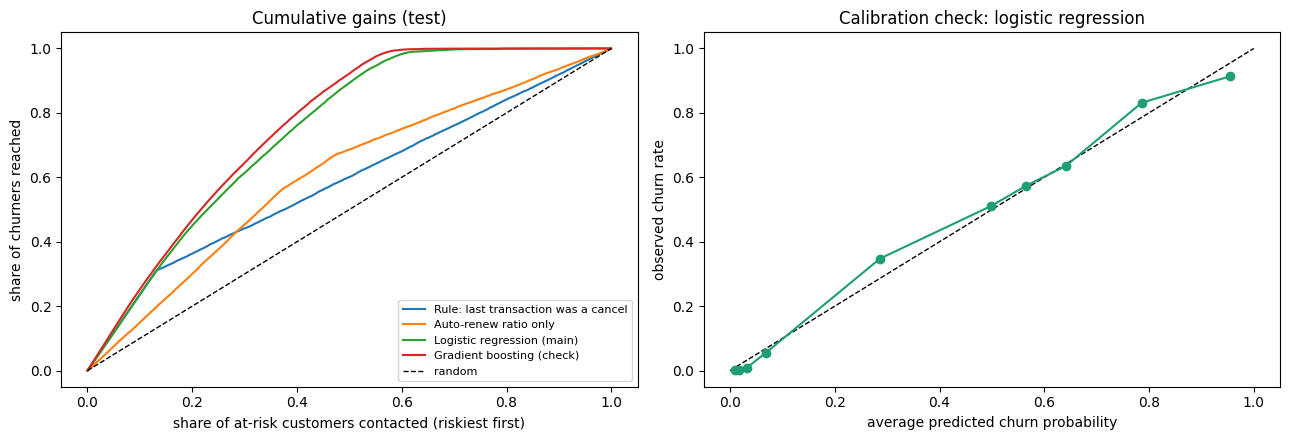

,decile,predicted,observed
0,0,0.010,0.001
1,1,0.018,0.002
2,2,0.032,0.009
3,3,0.069,0.056
4,4,0.286,0.348
5,5,0.499,0.511
6,6,0.564,0.573
7,7,0.641,0.635
8,8,0.786,0.831
9,9,0.955,0.914


In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, early_stopping=True, random_state=RANDOM_SEED)
gbm.fit(P.loc[idx_train, ALL_FEATURES].values, ytr.values)
p_gbm_te = gbm.predict_proba(P.loc[idx_test, ALL_FEATURES].values)[:, 1]

te = P.loc[idx_test].reset_index(drop=True)
scores = {"Rule: last transaction was a cancel": te["last_is_cancel"].values.astype(float),
          "Auto-renew ratio only": -te["auto_renew_ratio"].values,
          "Logistic regression (main)": p_logit_te,
          "Gradient boosting (check)": p_gbm_te}

def top_k(score, q):
    k = int(math.ceil(q * len(score))); m = np.zeros(len(score), bool); m[np.argsort(-score, kind="stable")[:k]] = True; return m

base = yte.mean(); rows = []
for name, s in scores.items():
    m = top_k(s, 0.10)
    rows.append({"model": name, "AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
                 "precision@top10%": yte[m].mean(), "recall@top10%": yte[m].sum() / yte.sum(), "lift@top10%": yte[m].mean() / base})
perf = pd.DataFrame(rows); display(perf.round(4)); perf.to_csv(os.path.join(EXPORT_DIR, "model_comparison.csv"), index=False)
print(f"Base churn rate in the at-risk pool (test): {base:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, s in scores.items():
    o = np.argsort(-s, kind="stable"); cum = np.cumsum(yte[o]) / yte.sum(); xs = np.arange(1, len(o) + 1) / len(o)
    axes[0].plot(xs[::20], cum[::20], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random"); axes[0].set_xlabel("share of at-risk customers contacted (riskiest first)")
axes[0].set_ylabel("share of churners reached"); axes[0].set_title("Cumulative gains (test)"); axes[0].legend(fontsize=8)
q = pd.qcut(pd.Series(p_logit_te).rank(method="first"), 10, labels=False)
cal = pd.DataFrame({"decile": q, "pred": p_logit_te, "obs": yte}).groupby("decile").agg(predicted=("pred", "mean"), observed=("obs", "mean")).reset_index()
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].plot(cal.predicted, cal.observed, "o-", color="#1D9E75")
axes[1].set_xlabel("average predicted churn probability"); axes[1].set_ylabel("observed churn rate"); axes[1].set_title("Calibration check: logistic regression")
plt.tight_layout(); plt.show(); display(cal.round(3)); cal.to_csv(os.path.join(EXPORT_DIR, "calibration_by_decile.csv"), index=False)

*Interview note:* "I evaluate the logistic model on a held-out test set using AUC, PR-AUC, precision/recall/lift in the top 10%, and a decile calibration check. I compare it with a simple cancellation rule and gradient boosting. In an interview, I quote the metrics printed by the latest complete run rather than assuming a result in advance."

*Your notes:*


## 9. From risk to decision: who should the retention team contact?

Contacting a customer costs money; a retained customer is worth money. For customer *i* with churn probability $p_i$ and value $V_i$:

$$\text{expected gain} = p_i \times s \times V_i - c \qquad\Rightarrow\qquad \text{contact if } p_i > \frac{c}{s\,V_i}$$

where *c* = cost of one outreach and *s* = chance that outreach saves a would-be churner. A **valuable** customer is worth contacting even at a lower churn probability; a **low-value** customer only at a high one. Ranking by expected gain is the same as ranking by **risk × value**.

> **These numbers are assumptions, not measurements.** I have no campaign data, so I cannot claim real ROI. I show a *scenario*, plus a sensitivity table that varies the assumptions.

In [34]:
ASSUME = dict(currency="NTD", outreach_cost=30.0, success_rate=0.20, horizon_months=6)   # c ~ 20% of one monthly plan
s_, c_ = ASSUME["success_rate"], ASSUME["outreach_cost"]
display(pd.Series(ASSUME, name="assumption").to_frame())

V = te["spend_raw"].values * ASSUME["horizon_months"]      # value at stake = monthly revenue x months we hope to keep
p = p_logit_te                                             # churn probability from the logistic regression
EV = p * s_ * V - c_

def policy_row(mask, name):
    k = int(mask.sum()); tp = int((mask & (yte == 1)).sum()); fp = int((mask & (yte == 0)).sum()); fn = int((~mask & (yte == 1)).sum())
    saved = s_ * V[mask & (yte == 1)].sum(); spent = c_ * k
    return {"policy": name, "contacted": k, "share_contacted": k / len(yte), "precision": tp / max(k, 1), "recall": tp / yte.sum(),
            "revenue_saved": saved, "outreach_cost": spent, "net_gain": saved - spent, "wasted_on_non_churners": c_ * fp,
            "revenue_missed_on_FN": s_ * V[~mask & (yte == 1)].sum()}

policies = {"Contact nobody": np.zeros(len(yte), bool), "Contact the whole at-risk pool": np.ones(len(yte), bool),
            "Rule: contact if last transaction was a cancel": te["last_is_cancel"].values == 1,
            "Top 10% by risk (fixed budget)": top_k(p, 0.10), "Expected gain > 0 (value-based)": EV > 0}
policy_df = pd.DataFrame([policy_row(m, n) for n, m in policies.items()])
display(policy_df.round(3)); policy_df.to_csv(os.path.join(EXPORT_DIR, "policy_comparison.csv"), index=False)
scale = len(P) / len(te)
b = policy_df.sort_values("net_gain", ascending=False).iloc[0]
print(f"Best scenario: '{b.policy}' -> net gain {b.net_gain:,.0f} {ASSUME['currency']} on the test pool; roughly {b.net_gain*scale:,.0f} if applied to the whole pool (x{scale:.1f}).")
print("Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.")

,assumption
currency,NTD
outreach_cost,30.0
success_rate,0.2
horizon_months,6


,policy,contacted,share_contacted,precision,recall,revenue_saved,outreach_cost,net_gain,wasted_on_non_churners,revenue_missed_on_FN
0,Contact nobody,0,0.000,0.000,0.000,0.000,0.0,0.000,0.0,1914281.589
1,Contact the whole at-risk pool,30320,1.000,0.388,1.000,1914281.589,909600.0,1004681.589,556800.0,0.000
2,Rule: contact if last transaction was a cancel,3972,0.131,0.916,0.309,549537.850,119160.0,430377.850,10020.0,1364743.740
3,Top 10% by risk (fixed budget),3032,0.100,0.914,0.236,401765.752,90960.0,310805.752,7860.0,1512515.837
4,Expected gain > 0 (value-based),16900,0.557,0.652,0.937,1838551.407,507000.0,1331551.407,176400.0,75730.182


Best scenario: 'Expected gain > 0 (value-based)' -> net gain 1,331,551 NTD on the test pool; roughly 5,326,206 if applied to the whole pool (x4.0).
Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.


**Break-even risk by customer value** (the rule *contact if p > c / (s × V)* gives a different threshold for each value level):

In [35]:
tier = pd.qcut(pd.Series(V).rank(method="first"), 3, labels=["Low value", "Mid value", "High value"]).values
ev_mask = EV > 0; rows = []
for t_ in ["Low value", "Mid value", "High value"]:
    m = tier == t_; medV = float(np.median(V[m]))
    rows.append({"value tier": t_, "customers": int(m.sum()), "median value (NTD)": round(medV), "break-even churn probability": round(min(c_ / (s_ * medV), 1), 3),
                 "share contacted": round(float((ev_mask & m).mean() / m.mean()), 3),
                 "precision of contacted": round(float(yte[ev_mask & m].mean()) if (ev_mask & m).any() else float("nan"), 3)})
tier_df = pd.DataFrame(rows); display(tier_df); tier_df.to_csv(os.path.join(EXPORT_DIR, "threshold_by_value_tier.csv"), index=False)

,value tier,customers,median value (NTD),break-even churn probability,share contacted,precision of contacted
0,Low value,10107,594,0.253,0.346,0.794
1,Mid value,10106,844,0.178,0.703,0.606
2,High value,10107,935,0.160,0.623,0.625


**Sensitivity:** how does the result change if my assumptions are wrong?

In [36]:
succ_grid, cost_grid = [0.10, 0.20, 0.30, 0.40], [10, 20, 30, 60]
net = pd.DataFrame(index=[f"cost={c}" for c in cost_grid], columns=[f"success={s}" for s in succ_grid], dtype=float)
for c in cost_grid:
    for s in succ_grid:
        m = (p * s * V - c) > 0
        net.loc[f"cost={c}", f"success={s}"] = s * V[m & (yte == 1)].sum() - c * m.sum()
print("Net gain (test pool) of the value-based policy under different assumptions:"); display(net.round(0))
net.to_csv(os.path.join(EXPORT_DIR, "sensitivity_net_gain.csv"))
print(f"Net gain is positive in {int((net > 0).sum().sum())} of {net.size} scenarios (worst {net.min().min():,.0f}, best {net.max().max():,.0f}). "
      "The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.")

Net gain (test pool) of the value-based policy under different assumptions:


,success=0.1,success=0.2,success=0.3,success=0.4
cost=10,761596.0,1709179.0,2657851.0,3602637.0
cost=20,580214.0,1523191.0,2472696.0,3418358.0
cost=30,411455.0,1331551.0,2284787.0,3238803.0
cost=60,75243.0,822910.0,1740643.0,2663103.0


Net gain is positive in 16 of 16 scenarios (worst 75,243, best 3,602,637). The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.


In [37]:
rank = pd.DataFrame({"msno": te.msno, "churn_probability": p, "value_at_stake": V, "risk_x_value": p * V, "expected_gain": EV,
                     "contact": EV > 0, "actually_churned": yte, "auto_renew_group": te.auto_renew_group, "plan_group": te.plan_group,
                     "tenure_group": te.tenure_group, "cancel_history": te.cancel_history})
rank["priority_rank"] = rank.expected_gain.rank(ascending=False, method="first").astype(int)
rank = rank.sort_values("priority_rank")
print(f"Flagged for outreach: {int(rank.contact.sum()):,} of {len(rank):,} at-risk customers in the test set")
display(rank.head(10).round(3))

Flagged for outreach: 16,900 of 30,320 at-risk customers in the test set


,msno,churn_probability,value_at_stake,risk_x_value,expected_gain,contact,actually_churned,auto_renew_group,plan_group,tenure_group,cancel_history,priority_rank
23356,zCSyBmPFj9l2MHL/HYBb5nTejB8E+xR+UmYmji7tJP4=,0.835,4762.703,3975.840,765.168,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,1
22584,kCdVCmbWKPV/hs5uQhnxvhOrDyAt2yX7OLPI/CDxAsM=,0.725,5224.865,3788.604,727.721,True,0,low auto-renew,8-30d plan,>2 years,never cancelled,2
1627,Q5vEat5l75rbtkRaiIqbxxxVu7C9AgH1D45DlGBaJ3w=,0.670,4266.818,2859.052,541.810,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,3
25214,MrqQI9LsIH1a+PqJV0nMbsNJs0SH4iaDFCw5tEzpQL0=,0.663,4203.093,2787.562,527.512,True,1,low auto-renew,31-90d plan,>2 years,never cancelled,4
20602,0b8ApjfB8LE8//PLaQ4fwUNgy8yZN+sVPCkN5M/6ir8=,0.651,3762.000,2447.367,459.473,True,0,low auto-renew,8-30d plan,>2 years,never cancelled,5
9509,myDLzMmo+BJqSQUfaKjLnPIMljKIKKe2nCjM7AZDGLU=,0.702,3397.500,2383.365,446.673,True,0,low auto-renew,>90d plan,>2 years,never cancelled,6
29875,bxSu35YAF+l1kRu2EpZADMy2niLV+UCdUhk7N/kY6LU=,0.937,2389.901,2240.377,418.075,True,1,low auto-renew,<=7d plan,>2 years,never cancelled,7
14021,Vm6igmkSfwFU9PVpWEw1LBUkPHBK9++fzcQgj3iSZy4=,0.921,2220.517,2044.559,378.912,True,0,low auto-renew,<=7d plan,>2 years,never cancelled,8
16055,bR62eijNEya14HAdn1YUbKCIdJkAPY46vIJOYP/xvpI=,0.679,2806.000,1905.416,351.083,True,1,high auto-renew,8-30d plan,>2 years,has cancelled before,9
8820,VsYsv6sbSMtxvLTtNYDorB4L7qujH1WrRME2MnNAGGo=,0.933,1909.333,1781.400,326.280,True,0,medium auto-renew,8-30d plan,>2 years,has cancelled before,10


*Interview note:* "The model gives a churn probability; the business needs a decision. I turned it into a break-even rule: contact if the expected savings exceed the cost. Because customers differ in value, the threshold differs by value tier. All the money numbers are assumptions, so I show a sensitivity table and call it a scenario, not ROI."

*Your notes:*

## 10. Final audit and portfolio exports

This final section records methodological decisions and exports aggregate/model outputs for the dashboard. Run after the modelling and business-policy sections have completed. **Do not publish customer-level files containing `msno` or other customer identifiers.**

In [ ]:
from pathlib import Path
import pandas as pd

EXPORT_DIR = Path(EXPORT_DIR) if 'EXPORT_DIR' in globals() else Path('/content/dashboard_exports')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Export results already created above; this cell does not retrain models.
exports = {
    'model_comparison.csv': 'perf',
    'policy_comparison.csv': 'policy_df',
    'threshold_by_value_tier.csv': 'tier_df',
    'permutation_importance.csv': 'permutation_df',
}
for filename, variable_name in exports.items():
    obj = globals().get(variable_name)
    if isinstance(obj, pd.DataFrame):
        obj.to_csv(EXPORT_DIR / filename, index=False)
        print(f'Saved {filename}: {len(obj):,} rows')
    else:
        print(f'Skipped {filename}: {variable_name} was not created in this run')

audit_log = pd.DataFrame([
    {'check': 'Feature cutoff', 'status': 'PASS', 'detail': 'Transaction features use stg_txn filtered to transaction_date <= 2017-02-28.'},
    {'check': 'Forbidden target/diagnostic columns', 'status': 'PASS', 'detail': 'msno, is_churn_official, event variants, resolvable, duration, and last_expire are excluded from model inputs.'},
    {'check': 'Stratified split reproducibility', 'status': 'PASS', 'detail': '80/20 split recreated exactly with random_state=42 and stratify=y.'},
    {'check': 'Train/test overlap', 'status': 'PASS', 'detail': 'Zero overlapping row indices.'},
    {'check': 'Cancellation feature sensitivity', 'status': 'REVIEWED', 'detail': 'Removing last_is_cancel changed ROC-AUC 0.9835 to 0.9812 and PR-AUC 0.8178 to 0.7905; historical availability does not by itself prove absence of target-proximity concerns.'},
    {'check': 'Survival analysis', 'status': 'LIMITATION DOCUMENTED', 'detail': 'Do not claim conventional KM/Cox estimates; the current event time is a 30-day confirmation endpoint, not observed actual churn time.'},
    {'check': 'Customer-level dashboard export', 'status': 'DO NOT PUBLISH', 'detail': 'Do not upload customer-level data containing msno to a public repository.'},
] )
audit_log.to_csv(EXPORT_DIR / 'model_audit_log.csv', index=False)
print(f'\nSaved model_audit_log.csv to {EXPORT_DIR}')
